In [3]:
from ase.io.trajectory import Trajectory 
from ase.md.langevin import Langevin 
from ase.md.velocitydistribution import MaxwellBoltzmannDistribution 

import numpy as np 
#from mace.calculators import mace_mp,mace_off 
from chgnet.model.dynamics import CHGNetCalculator 
from chgnet.model import CHGNet 
from ase import units 

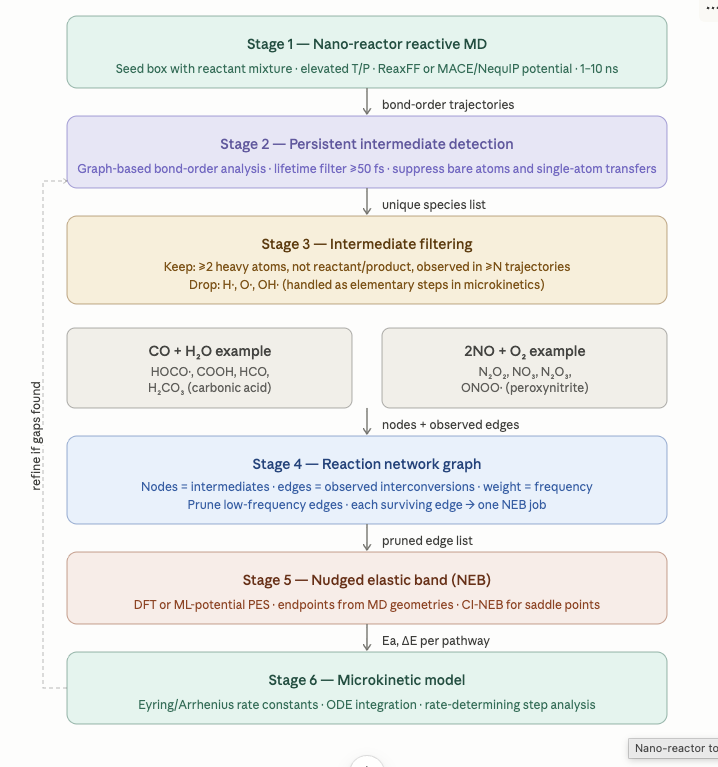

## 1. build the cell (Forward)

In [4]:
from smilesbox.smilesbox import SMILESbox
#smiles = ["N#N","O=O","O=O"]
#smiles = ["N(=O)[O]","N(=O)[O]"]
#smiles = ["C(=O)=O","[HH]"] # forward 
#smiles = ["[HH]","[HH]","O=O"]
smiles = ["[N]=O","[N]=O","O=O"]
sm = SMILESbox(
    smiles = smiles * 4,
    box_size=20,
    min_distance=1.0
)
atoms = sm.atoms

In [5]:
calculator = CHGNetCalculator(use_device="mps", on_isolated_atoms="ignore")
#calculator = mace_off(model="small")
#calculator = EMT()

CHGNet v0.3.0 initialized with 412,525 parameters
CHGNet will run on mps



NanoReactor starting
  24 atoms | T=4500 K | NVT
  40000 steps × 0.25 fs = 10.0 ps
  τ_min = 10 fs | BO cutoffs = defaults (0.3)
  Output → reactor_output_reaction_4_forward_chgnet

Running MD...
  [SpeciesTracker] processed 500 frames, 2 unique formulae seen
  [SpeciesTracker] processed 1000 frames, 2 unique formulae seen
  [SpeciesTracker] processed 1500 frames, 3 unique formulae seen
  [SpeciesTracker] processed 2000 frames, 3 unique formulae seen
  [SpeciesTracker] processed 2500 frames, 3 unique formulae seen
  [SpeciesTracker] processed 3000 frames, 4 unique formulae seen
  [SpeciesTracker] processed 3500 frames, 4 unique formulae seen
  [SpeciesTracker] processed 4000 frames, 4 unique formulae seen
  [SpeciesTracker] processed 4500 frames, 4 unique formulae seen
  [SpeciesTracker] processed 5000 frames, 5 unique formulae seen
  [SpeciesTracker] processed 5500 frames, 5 unique formulae seen
  [SpeciesTracker] processed 6000 frames, 5 unique formulae seen
  [SpeciesTracker] proce

AttributeError: module 'matplotlib.cm' has no attribute 'get_cmap'

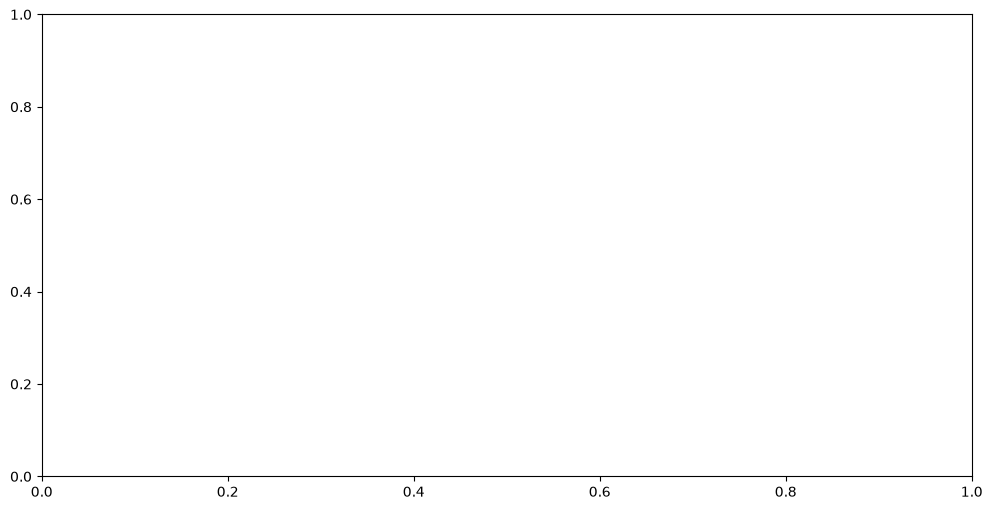

In [6]:
from ase.io import read
from claude_code.nano_reactor import NanoReactor
import warnings 
warnings.simplefilter("ignore")
output_dir = "reactor_output_reaction_4_forward_chgnet"
reactor = NanoReactor(
    atoms        = atoms,
    calculator   = calculator,
    temperature  = 4500,          # K
    total_time_fs= 10000,       # 100 ps
    timestep_fs  = 0.25,
    tau_min_fs   = 10,
    reactants    = {"NO","O2"},
    products     = {"NO2"},
    output_dir   = output_dir,
)

reactor.run()
reactor.report()
reactor.save_summary_csv(f"{output_dir}/results.csv")
reactor.plot()

In [ ]:
plt.cm.tab20

<bound method NanoReactor.get_intermediates of <claude_code.nano_reactor.NanoReactor object at 0x13a3b7ef0>>


[SpeciesTracker] Intermediates passing all filters (τ_min=10 fs, heavy≥2, freq≥0.0%):
  NO3           max_lifetime=23.5 fs  appearances=666
  N2O2          max_lifetime=23.2 fs  appearances=678
  O4            max_lifetime=18.8 fs  appearances=220


SyntaxError: 'return' outside function (1518538955.py, line 34)

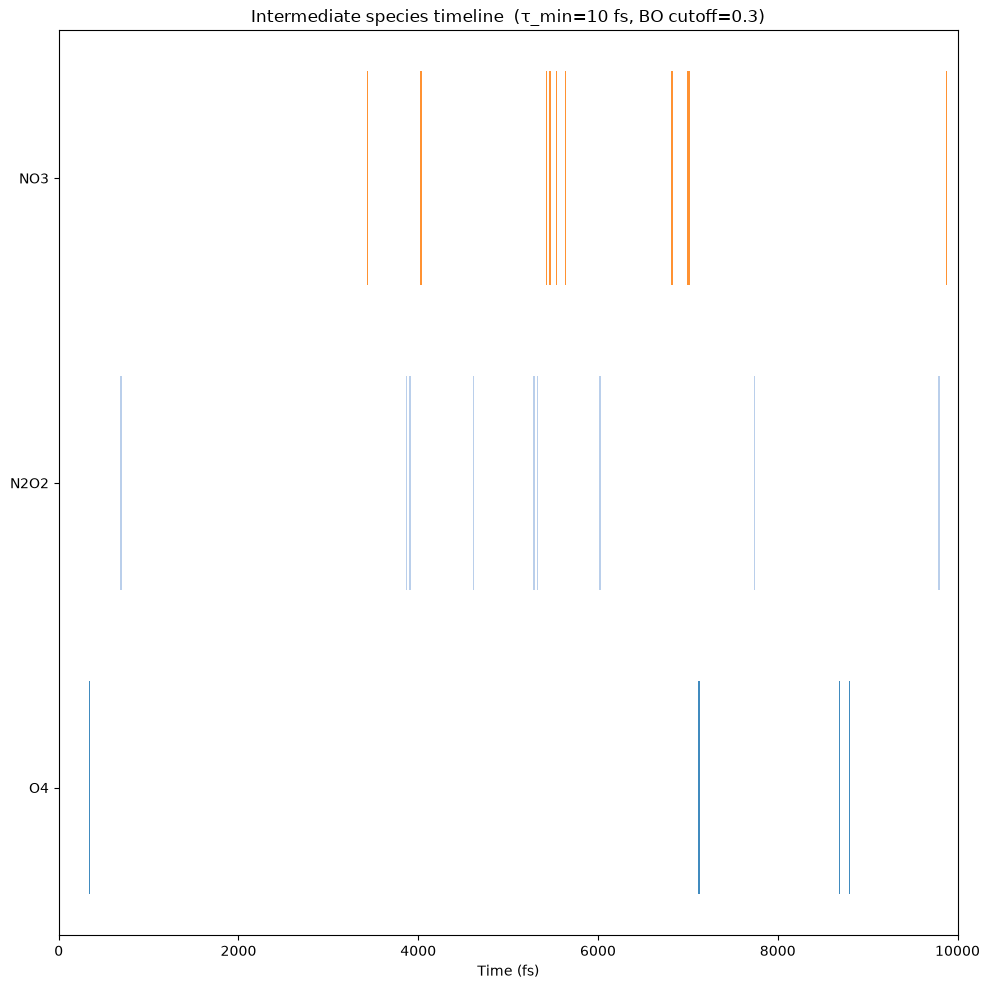

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

intermediates = reactor.get_intermediates()
# Sort by first appearance
sorted_items = sorted(
    intermediates.items(),
    key=lambda x: min(x[1].frame_indices),
)[:10]

total_time_fs = 40000 * reactor.timestep_fs
fig, ax = plt.subplots(figsize=(10,10))

cmap = plt.cm.tab20
for row_idx, (formula, rec) in enumerate(sorted_items):
    color = cmap(row_idx)
    for start_f, end_f, _ in rec.runs:
        t_start = start_f * reactor.timestep_fs
        t_end = end_f * reactor.timestep_fs
        ax.barh(
            row_idx, t_end - t_start,
            left=t_start, height=0.7,
            color=color, alpha=0.85,
        )

ax.set_yticks(range(len(sorted_items)))
ax.set_yticklabels([f for f, _ in sorted_items], fontsize=10)
ax.set_xlabel("Time (fs)")
ax.set_xlim(0, total_time_fs)
ax.set_title(f"Intermediate species timeline  "
             f"(τ_min={reactor.tau_min_fs} fs, BO cutoff=0.3)")
ax.axvline(0, color="k", lw=0.5)
plt.tight_layout()
#return fig, ax

## 2. Reverse

In [23]:
from smilesbox.smilesbox import SMILESbox
#smiles = ["N#N","O=O","O=O"]
#smiles = ["N(=O)[O]","N(=O)[O]"]
#smiles = ["C(=O)=O","[HH]"] # forward 
#smiles = ["O","[C-]#[O+]"] # reverse 
#smiles = ["O","O"]
smiles = ["N(=O)[O]","N(=O)[O]"]
sm = SMILESbox(
    smiles = smiles * 4,
    box_size=20,
    min_distance=1.0
)
atoms = sm.atoms

In [ ]:
#calculator = CHGNetCalculator(use_device="mps", on_isolated_atoms="ignore")

CHGNet v0.3.0 initialized with 412,525 parameters
CHGNet will run on mps



NanoReactor starting
  24 atoms | T=4500 K | NVT
  40000 steps × 0.25 fs = 10.0 ps
  τ_min = 10 fs | BO cutoffs = defaults (0.3)
  Output → reactor_output_reaction_4_reverse_chgnet

Running MD...
  [SpeciesTracker] processed 500 frames, 3 unique formulae seen
  [SpeciesTracker] processed 1000 frames, 5 unique formulae seen
  [SpeciesTracker] processed 1500 frames, 5 unique formulae seen
  [SpeciesTracker] processed 2000 frames, 5 unique formulae seen
  [SpeciesTracker] processed 2500 frames, 5 unique formulae seen
  [SpeciesTracker] processed 3000 frames, 5 unique formulae seen
  [SpeciesTracker] processed 3500 frames, 5 unique formulae seen
  [SpeciesTracker] processed 4000 frames, 5 unique formulae seen
  [SpeciesTracker] processed 4500 frames, 5 unique formulae seen
  [SpeciesTracker] processed 5000 frames, 5 unique formulae seen
  [SpeciesTracker] processed 5500 frames, 5 unique formulae seen
  [SpeciesTracker] processed 6000 frames, 5 unique formulae seen
  [SpeciesTracker] proce

AttributeError: module 'matplotlib.cm' has no attribute 'get_cmap'

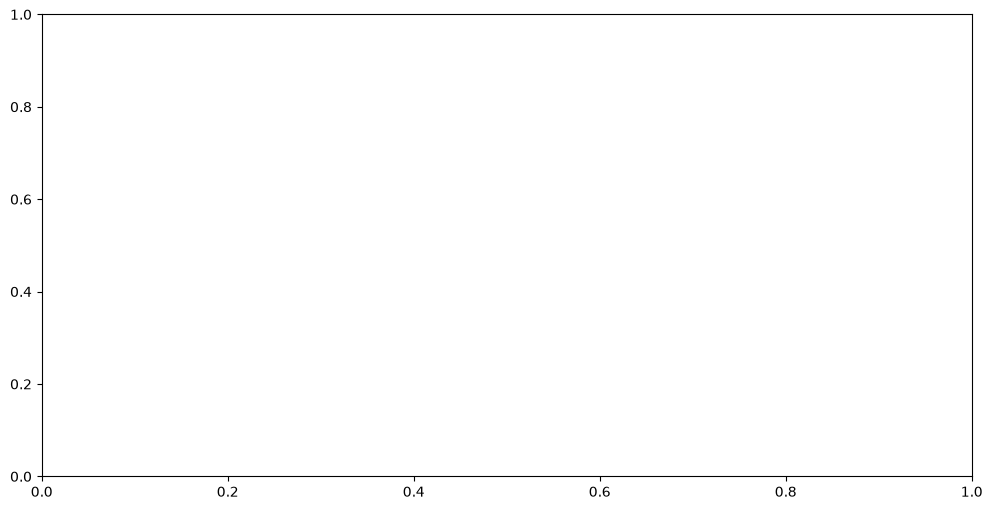

In [24]:
from ase.io import read
from claude_code.nano_reactor import NanoReactor
import warnings 
warnings.simplefilter("ignore")
output_dir = "reactor_output_reaction_4_reverse_chgnet"
reactor = NanoReactor(
    atoms        = atoms,
    calculator   = calculator,
    temperature  = 4500,          # K
    total_time_fs= 10000,       # 100 ps
    timestep_fs  = 0.25,
    tau_min_fs   = 10,
    reactants    = {"NO2"},
    products     = {"NO","O2"},
    output_dir   = output_dir,
)

reactor.run()
reactor.report()
reactor.save_summary_csv(f"{output_dir}/results.csv")
reactor.plot()


[SpeciesTracker] Intermediates passing all filters (τ_min=10 fs, heavy≥2, freq≥0.0%):
  NO3           max_lifetime=1566.5 fs  appearances=19482
  N2O4          max_lifetime=50.5 fs  appearances=583
  N2O2          max_lifetime=37.8 fs  appearances=188
  N2O3          max_lifetime=22.8 fs  appearances=229


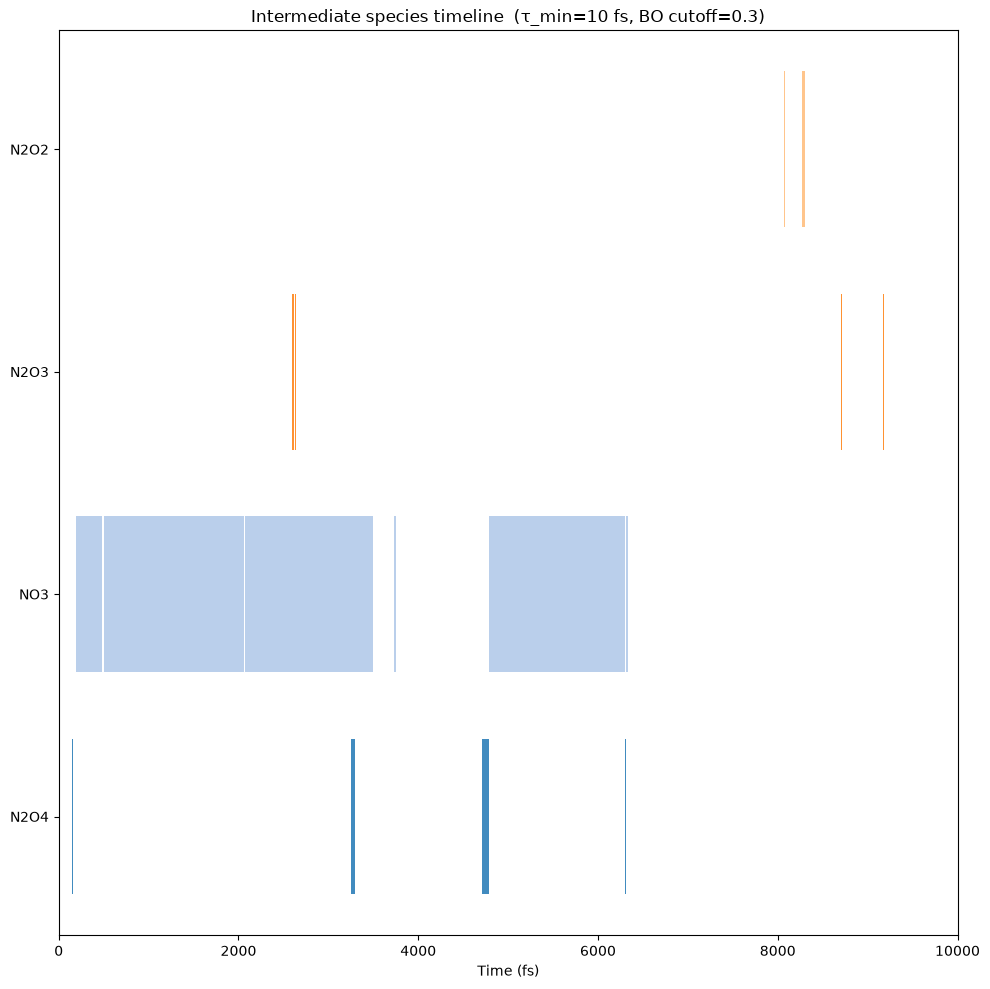

In [25]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

intermediates = reactor.get_intermediates()
# Sort by first appearance
sorted_items = sorted(
    intermediates.items(),
    key=lambda x: min(x[1].frame_indices),
)[:10]

total_time_fs = 40000 * reactor.timestep_fs
fig, ax = plt.subplots(figsize=(10,10))

cmap = plt.cm.tab20
for row_idx, (formula, rec) in enumerate(sorted_items):
    color = cmap(row_idx)
    for start_f, end_f, _ in rec.runs:
        t_start = start_f * reactor.timestep_fs
        t_end = end_f * reactor.timestep_fs
        ax.barh(
            row_idx, t_end - t_start,
            left=t_start, height=0.7,
            color=color, alpha=0.85,
        )

ax.set_yticks(range(len(sorted_items)))
ax.set_yticklabels([f for f, _ in sorted_items], fontsize=10)
ax.set_xlabel("Time (fs)")
ax.set_xlim(0, total_time_fs)
ax.set_title(f"Intermediate species timeline  "
             f"(τ_min={reactor.tau_min_fs} fs, BO cutoff=0.3)")
ax.axvline(0, color="k", lw=0.5)
plt.tight_layout()
#return fig, ax

speed testing 

In [11]:
import itertools as it 
from collections import defaultdict
from smilesbox.smilesbox import SMILESbox
from claude_code.nano_reactor import NanoReactor
import os 
import datetime

In [12]:
box_sizes = [5,10,15,20]
mol_multiplication = [1,2,4,8]
min_distances = [0.5,1.0,2.0]
total_time = [1000,2000,5000,100000]

In [13]:
combinations = list(it.product(box_sizes,mol_multiplication,min_distances,total_time))
combinations

[(5, 1, 0.5, 1000),
 (5, 1, 0.5, 2000),
 (5, 1, 0.5, 5000),
 (5, 1, 0.5, 100000),
 (5, 1, 1.0, 1000),
 (5, 1, 1.0, 2000),
 (5, 1, 1.0, 5000),
 (5, 1, 1.0, 100000),
 (5, 1, 2.0, 1000),
 (5, 1, 2.0, 2000),
 (5, 1, 2.0, 5000),
 (5, 1, 2.0, 100000),
 (5, 2, 0.5, 1000),
 (5, 2, 0.5, 2000),
 (5, 2, 0.5, 5000),
 (5, 2, 0.5, 100000),
 (5, 2, 1.0, 1000),
 (5, 2, 1.0, 2000),
 (5, 2, 1.0, 5000),
 (5, 2, 1.0, 100000),
 (5, 2, 2.0, 1000),
 (5, 2, 2.0, 2000),
 (5, 2, 2.0, 5000),
 (5, 2, 2.0, 100000),
 (5, 4, 0.5, 1000),
 (5, 4, 0.5, 2000),
 (5, 4, 0.5, 5000),
 (5, 4, 0.5, 100000),
 (5, 4, 1.0, 1000),
 (5, 4, 1.0, 2000),
 (5, 4, 1.0, 5000),
 (5, 4, 1.0, 100000),
 (5, 4, 2.0, 1000),
 (5, 4, 2.0, 2000),
 (5, 4, 2.0, 5000),
 (5, 4, 2.0, 100000),
 (5, 8, 0.5, 1000),
 (5, 8, 0.5, 2000),
 (5, 8, 0.5, 5000),
 (5, 8, 0.5, 100000),
 (5, 8, 1.0, 1000),
 (5, 8, 1.0, 2000),
 (5, 8, 1.0, 5000),
 (5, 8, 1.0, 100000),
 (5, 8, 2.0, 1000),
 (5, 8, 2.0, 2000),
 (5, 8, 2.0, 5000),
 (5, 8, 2.0, 100000),
 (10, 1, 0.5, 10

In [21]:
smiles = ["N#N","O=O","O=O"]
timings = defaultdict(dict)
calculator = CHGNetCalculator(use_device="mps", on_isolated_atoms="ignore")
for bs,mm,md,tt in combinations:
    try:
        print(f"box_size:{bs},min_mol:{mm},min_dist:{md},total_time:{tt}\n")
        location = f"speed_testing/boxsize_{bs}/mol_multiplication_{mm}/min_dist_{md}/total_time_{tt}"
        os.makedirs(location,exist_ok=True)
        sm = SMILESbox(
            smiles = smiles * mm,
            box_size=bs,
            min_distance=md
        )
        atoms = sm.atoms

        reactor = NanoReactor(
        atoms        = atoms,
        calculator   = calculator,
        temperature  = 4500,          # K
        total_time_fs= tt,       # 100 ps
        timestep_fs  = 0.25,
        tau_min_fs   = 10,
        reactants    = {"N2","O2"},
        products     = {"NO2"},
        output_dir   = location,
    )
        start = datetime.datetime.now()
        reactor.run()
        end = datetime.datetime.now()
        total = end - start
        timings[bs][mm][md][tt] = total.total_seconds()
        reactor.report()
        reactor.save_summary_csv(f"{location}/results.csv")


    except Exception as e:
        print(f"         ERROR:{e}\n") 


CHGNet v0.3.0 initialized with 412,525 parameters
CHGNet will run on mps
box_size:5,min_mol:1,min_dist:0.5,total_time:1000

         ERROR:Could not place all molecules without overlap after 100000 attempts. Try a larger box or reduce min_distance/margin.

box_size:5,min_mol:1,min_dist:0.5,total_time:2000

         ERROR:Could not place all molecules without overlap after 100000 attempts. Try a larger box or reduce min_distance/margin.

box_size:5,min_mol:1,min_dist:0.5,total_time:5000

         ERROR:Could not place all molecules without overlap after 100000 attempts. Try a larger box or reduce min_distance/margin.

box_size:5,min_mol:1,min_dist:0.5,total_time:100000

         ERROR:Could not place all molecules without overlap after 100000 attempts. Try a larger box or reduce min_distance/margin.

box_size:5,min_mol:1,min_dist:1.0,total_time:1000

         ERROR:Could not place all molecules without overlap after 100000 attempts. Try a larger box or reduce min_distance/margin.

box_s

KeyboardInterrupt: 